# Lecture 4 — Class Exercise
## Scatter & Bubble Charts: Gapminder

> **Push to:** `week04/lecture04_exercise.ipynb`

**Rules:**
1. Colour used **sparingly** — one categorical variable, no rainbow
2. If showing all continents, either use accessible palette OR grey all + highlight one
3. `size_max` set when using bubble size
4. Log scale for GDP per capita
5. Insight title

---


In [1]:
import pandas as pd
import plotly.express as px


# Dataset: Gapminder — GDP, Life Expectancy, Population by Country
# Source: Gapminder Foundation (gapminder.org)

df = px.data.gapminder()
print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 1704 rows
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [2]:
# explore

print(df.info())
print("Years:", sorted(df['year'].unique()))
print("Continents:", df['continent'].unique())
print(df.describe().round(1))


<class 'pandas.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   str    
 1   continent  1704 non-null   str    
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   str    
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), str(3)
memory usage: 106.6 KB
None
Years: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Continents: <StringArray>
['Asia', 'Europe', 'Africa', 'Americas', 'Oceania']
Length: 5, dtype: str
         year  lifeExp           pop  gdpPercap  iso_num
count  1704.0   1704.0  1.704000e+03     1704.0   1704.0
mean   1979.5     59.5  2.

## Task 1 — Scatter: life expectancy change over time

**What to build:** A scatter showing **GDP per capita vs life expectancy** for **two years** (2002 and 2007) to show how both moved — use **colour for year** (just 2 colours), **one continent only**.

Choose any continent except Africa (that was the example). Highlight the change direction.

> 💡 Filter: `df.loc[df['continent'] == 'YOUR_CHOICE']` then filter years


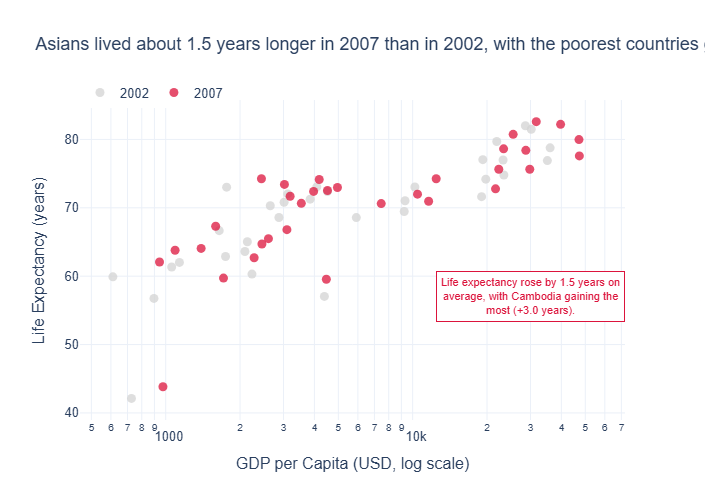

In [3]:
# Task 1
# YOUR CODE HERE
import math

asia = df.loc[(df['continent'] == 'Asia') & (df['year'].isin([2002, 2007]))].copy()
asia['year'] = asia['year'].astype(str)      # categorical -> only 2 colours

colour_map = {'2002': 'lightgrey', '2007': 'crimson'}

fig = px.scatter(
    data_frame=asia, x='gdpPercap', y='lifeExp',
    color='year',
    color_discrete_map=colour_map,
    hover_name='country',
    log_x=True,                              # log scale: wealth is non-linear
    labels={'gdpPercap': 'GDP per Capita (USD, log scale)', 'lifeExp': 'Life Expectancy (years)', 'year': ''},
    template='plotly_white',
    title='Asians lived about 1.5 years longer in 2007 than in 2002, with the poorest countries gaining most'
)

fig.update_traces(
    hovertemplate='<b>%{hovertext}</b><br>'
                  'GDP per capita: $%{x:,.0f}<br>'
                  'Life expectancy: %{y:.1f} yrs<extra></extra>'
)
fig.update_traces(marker=dict(size=9, opacity=0.75))

fig.add_annotation(
    x=math.log10(30000), y=57,
    text='Life expectancy rose by 1.5 years on<br>average, with Cambodia gaining the<br>most (+3.0 years).',
    showarrow=False,
    font=dict(color='crimson', size=11, family='Arial'),
    bgcolor='white', bordercolor='crimson', borderwidth=1, borderpad=4
)

fig.update_layout(
    font=dict(family='Arial', size=13),
    height=500,
    legend=dict(orientation='h', x=0, y=1.07, title='')
)
fig.show()

## Task 2 — Bubble chart: tell a story

**What to build:** A bubble chart (full 2007 dataset, all countries) where:
- x = GDP per capita (log scale)
- y = life expectancy
- size = population
- colour = ONE continent highlighted (your choice), all others grey
- At least one annotation explaining the highlighted group's story

> This is the grey-and-highlight technique applied to a bubble chart.


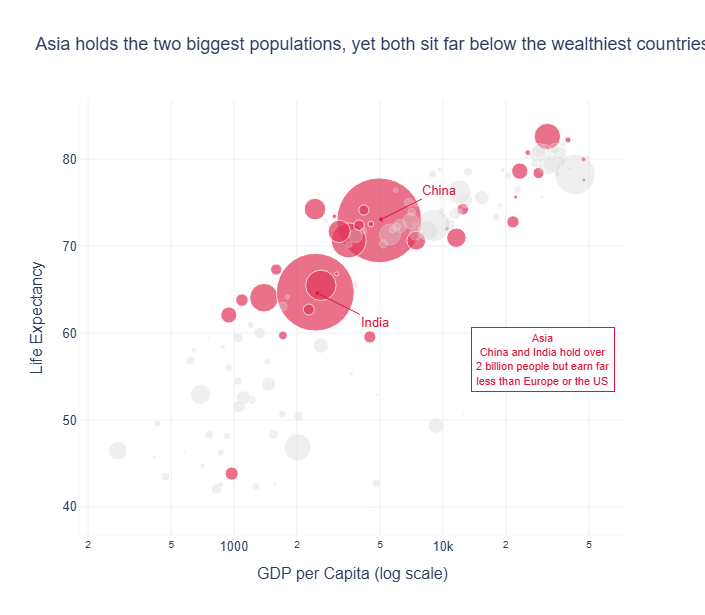

In [4]:
# Task 2
# YOUR CODE HERE
df07 = df.loc[df['year'] == 2007].copy()

highlight_continent = 'Asia'
colour_map = {c: ('crimson' if c == highlight_continent else 'lightgrey') for c in df07['continent'].unique()}

fig = px.scatter(
    data_frame=df07, x='gdpPercap', y='lifeExp',
    size='pop',
    color='continent',
    color_discrete_map=colour_map,
    hover_name='country',
    hover_data={'continent': False},
    log_x=True,
    size_max=60,                             # cap bubble size so small countries still visible
    labels={'gdpPercap': 'GDP per Capita (log scale)', 'lifeExp': 'Life Expectancy', 'pop': 'Population'},
    template='plotly_white',
    custom_data=['country', 'pop'],
    opacity=0.7,
    title='Asia holds the two biggest populations, yet both sit far below the wealthiest countries'
)

# Improve hover: show formatted population using HTML
fig.update_traces(
    hovertemplate='<b>%{hovertext}</b><br>'
                  'GDP per capita: $%{x:,.0f}<br>'
                  'Life expectancy: %{y:.1f} yrs<br>'
                  'Population: %{customdata[1]:,.0f}<extra></extra>'
)

# highlighted continent gets a stronger look, the rest fade back
fig.update_traces(selector=dict(name=highlight_continent), opacity=0.85)
fig.update_traces(selector=lambda t: t.name != highlight_continent, opacity=0.5)

# label China and India directly
for country, ax, ay in [('China', 60, -30), ('India', 60, 30)]:
    row = df07[df07['country'] == country].iloc[0]
    fig.add_annotation(
        x=math.log10(row['gdpPercap']), y=row['lifeExp'],
        text=country,
        showarrow=True, arrowcolor='crimson', arrowhead=1, ax=ax, ay=ay,
        font=dict(size=13, family='Arial', color='crimson')
    )

# annotation explaining the highlighted group's story
fig.add_annotation(
    x=math.log10(30000), y=57,
    text='Asia<br>China and India hold over<br>2 billion people but earn far<br>less than Europe or the US',
    showarrow=False,
    font=dict(color='crimson', size=11, family='Arial'),
    bgcolor='white', bordercolor='crimson', borderwidth=1, borderpad=4
)

fig.update_layout(
    font=dict(family='Arial', size=13),
    yaxis=dict(linewidth=0.5), xaxis=dict(linewidth=0.5),
    showlegend=False,
    height=600, width=1100
)
fig.show()

